# Optimizer

Một mạng đã có gradient đúng nhưng loss lắc qua lại: giảm learning rate thì đi quá chậm, tăng lại thì văng khỏi vùng tốt. Đây giống việc đi trong một thung lũng hẹp: chiều dốc cần bước ngắn, chiều thoải cần tiến dài. Optimizer quyết định biến gradient thành bước cập nhật; ta sẽ kiểm SGD, momentum và Adam trên một mặt loss biết rõ trước khi chọn chúng cho dữ liệu thật.

> **Mục tiêu sau bài này**
>
> - Tính một bước SGD, momentum và Adam trên số nhỏ; tìm ngưỡng learning rate của một hàm bậc hai.
> - Giải thích các trạng thái optimizer giữ giữa các bước và vì sao phải lưu chúng khi chạy tiếp.
> - Phân biệt L2 regularization và weight decay kiểu AdamW.
> - Đọc lịch step, cosine, warmup và so optimizer bằng thực nghiệm công bằng.

## Gradient chỉ độ dốc, optimizer chọn bước

SGD cập nhật $w_{t+1}=w_t-\eta g_t$. Chữ stochastic đến từ việc tính $g_t$ trên một minibatch lấy ngẫu nhiên thay vì trên toàn bộ dữ liệu. Gradient của một minibatch lệch khỏi gradient đầy đủ một ít, nhưng khi minibatch được lấy ngẫu nhiên đều thì kỳ vọng của nó đúng bằng gradient đầy đủ: mỗi bước rẻ hơn nhiều, đổi lại đường đi hơi nhiễu. Learning rate $\eta$ quyết định độ dài bước, nên cùng một gradient mà các optimizer vẫn đi khác nhau. Các thuật toán dùng gradient để cập nhật trọng số như SGD, Adam gọi chung là optimizer.

Có ba cỡ dữ liệu cho mỗi bước. Gradient descent dùng cả tập: gradient chính xác nhưng mỗi bước đắt. SGD thuần dùng một mẫu: rất rẻ nhưng rất nhiễu; một epoch $N$ bước tốn cỡ một bước trên cả tập mà cập nhật được $N$ lần. Minibatch đứng giữa và là cách dùng mặc định. Nhiễu của gradient minibatch có độ lệch chuẩn tỉ lệ $1/\sqrt B$: tăng batch từ 16 lên 64 thì nhiễu giảm một nửa, còn batch quá nhỏ làm đường đi chập chờn. Tăng batch $k$ lần thì số bước mỗi epoch giảm $k$ lần; quy tắc tỉ lệ tuyến tính cho SGD nhân learning rate với $k$, thường kèm warmup, và vẫn phải kiểm lại trên validation.

**Hỏi nhanh.** So gradient tính trên một minibatch (SGD) với gradient tính trên toàn bộ dữ liệu (GD). Câu nào đúng?

- A. Bước SGD nào cũng đưa tham số lại gần nghiệm tối ưu hơn
- B. Kỳ vọng của gradient SGD bằng gradient của GD
- C. Gradient của GD có phương sai lớn hơn gradient của SGD
- D. SGD và GD chỉ hội tụ khi hàm mục tiêu lồi chặt

<details><summary>Đáp án</summary>

B. Kỳ vọng của gradient SGD bằng gradient của GD

Nếu minibatch được lấy ngẫu nhiên đều, thì trung bình trên mọi cách lấy đúng bằng gradient đầy đủ. Từng bước SGD vẫn có thể đi lệch, thậm chí ra xa nghiệm, vì gradient của một minibatch có nhiễu. Nhiễu lấy mẫu là của SGD; GD dùng mọi mẫu nên không có. Lồi chặt không phải điều kiện bắt buộc: gradient descent vẫn hội tụ trên nhiều hàm không lồi chặt khi learning rate phù hợp.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q1.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=5)

</details>

Một mặt loss kiểm nhỏ là $J(w_1,w_2)=w_1^2+8w_2^2$. Gradient $(2w_1,16w_2)$ thay đổi gắt theo chiều $w_2$, nên một bước SGD tách thành hai phép nhân độc lập: $w_1\leftarrow(1-2\eta)w_1$ và $w_2\leftarrow(1-16\eta)w_2$. Chiều $w_2$ chỉ ổn định khi $|1-16\eta|<1$, tức $0<\eta<1/8$; ngay cả với $\eta$ sát $1/8$, chiều $w_1$ vẫn chỉ được nhân $1-2/8=0.75$ mỗi bước. Tổng quát với hàm bậc hai, chiều cong nhất (trị riêng lớn nhất $\lambda_{\max}$ của Hessian, ở đây 16) đặt ngưỡng $\eta<2/\lambda_{\max}$, còn chiều thoải nhất (ở đây 2) quyết định tốc độ. Độ cong hai chiều càng chênh, thung lũng càng hẹp và SGD càng chậm. Con số $1/8$ là ngưỡng của riêng hàm này; trong mạng neural, độ cong đổi theo từng vùng của mặt loss.



**Hỏi nhanh.** Đổi mặt loss thành $J = w_1^2 + 50w_2^2$. Learning rate của SGD phải dưới ngưỡng nào thì chiều $w_2$ không nổ?

- A. $\eta < 1$
- B. $\eta < 0.04$
- C. $\eta < 0.02$
- D. $\eta < 0.01$

<details><summary>Đáp án</summary>

C. $\eta < 0.02$

Gradient theo $w_2$ là $100w_2$, nên mỗi bước nhân $w_2$ với $1 - 100\eta$. Cần $|1 - 100\eta| < 1$, tức $\eta < 2/100 = 0.02$. Ngưỡng $0.04 = 2/50$ là quên hệ số 2 khi lấy đạo hàm bình phương. $0.01$ là điều kiện để $w_2$ không đổi dấu, tức không đi zigzag, chưa phải điều kiện hội tụ. $\eta < 1$ chỉ là ngưỡng của chiều $w_1$. Ngay dưới $0.02$, chiều $w_1$ chỉ được nhân $1 - 2\cdot 0.02 = 0.96$ mỗi bước: thung lũng càng hẹp thì SGD càng chậm.

</details>

Nếu biết độ cong của mọi chiều, có thể chia bước cho độ cong: phương pháp Newton nhân gradient với nghịch đảo Hessian, và trên hàm bậc hai này nó tới đáy sau đúng một bước. Cái giá nằm ở kích thước. Mạng có $d$ tham số có Hessian $d\times d$; với $d=10^4$ đã là $10^8$ phần tử, và nghịch đảo tốn cỡ $d^3=10^{12}$ phép tính mỗi bước, trong khi phép cập nhật bậc một chỉ tốn cỡ $d$ phép tính sau khi backward đã cho gradient. Vì vậy deep learning dùng optimizer bậc một; momentum và Adam là những cách rẻ để bù một phần độ cong mà không cần dựng Hessian. Trên hàm bậc hai lồi, một bước Newton tới thẳng cực tiểu từ bất kỳ đâu; vì vậy với dữ liệu nhiều mà số tham số ít, như logistic regression, Newton cần rất ít bước dù mỗi bước đắt.

## Momentum nhớ hướng trước

Một quy ước thường dùng, cũng là dạng SGD momentum của PyTorch khi không bật dampening hay Nesterov, là

$$v_t=\mu v_{t-1}+g_t,\qquad w_{t+1}=w_t-\eta v_t.$$

$v$ cộng dồn gradient với hệ số nhớ $\mu\in[0,1)$. Gradient cùng dấu qua nhiều bước thì được cộng lên, bước dài dần; gradient đổi dấu qua lại thì triệt nhau một phần. Vì vậy momentum tiến nhanh dọc đáy thung lũng thoải và hãm dao động ở chiều dốc, nhưng quán tính quá lớn cũng đưa đường đi vượt đáy. $v$ là trạng thái số được optimizer lưu giữa các bước, không phải vận tốc vật lý.

**Hỏi nhanh.** $v$ cũ bằng 2, gradient mới bằng $-1$, $\mu = 0.9$. Theo quy ước $v \leftarrow \mu v + g$, $v$ mới bằng bao nhiêu?

- A. $-1$
- B. $-0.8$
- C. $0.8$
- D. $2.8$

<details><summary>Đáp án</summary>

C. $0.8$

$0.9\cdot 2 - 1 = 0.8$: hướng đi vẫn dương, vì ký ức của bước trước chưa mất hết. $-1$ là bước SGD thuần, bỏ qua $v$ cũ. $-0.8$ đúng độ lớn nhưng sai dấu, nhầm $v$ với hướng đi $-v$. $2.8$ là trừ gradient như khi cập nhật $w$, trong khi $v$ thì cộng gradient.

</details>



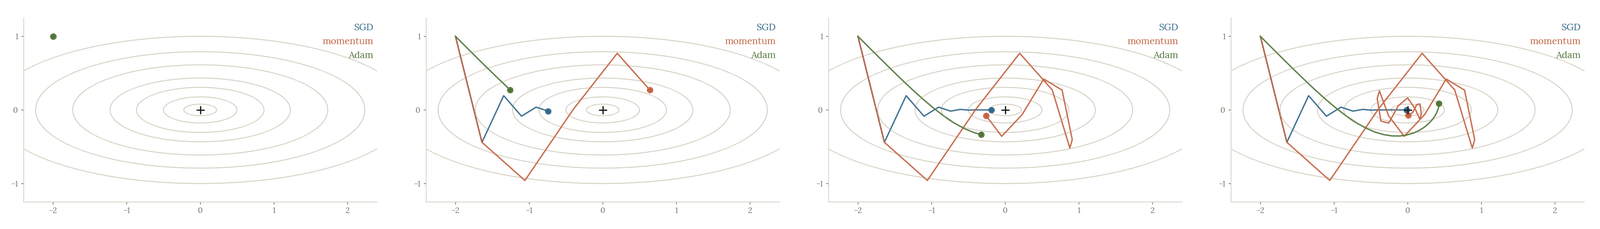

Hình chạy 25 bước trên $J=w_1^2+8w_2^2$ từ điểm $(-2,1)$ với $\eta=0.09$. SGD nhân $w_2$ với $1-16\cdot0.09=-0.44$ mỗi bước, nên $w_2$ đổi dấu liên tục: đường đi zigzag nhưng co nhanh. Chiều $w_1$ được nhân $0.82$ mỗi bước nên tiến đều về đáy. Thêm momentum $\mu=0.8$ với cùng $\eta$, quán tính tích lũy ở những bước đầu đưa đường đi vượt qua đáy rồi vòng lại: momentum bước dài hơn hẳn SGD, nên $\eta$ và $\mu$ phải chọn cùng nhau.

**Hỏi nhanh.** Gradient giữ nguyên bằng $g$ qua rất nhiều bước, $\mu = 0.9$, quy ước $v \leftarrow \mu v + g$. Về sau, bước $\eta v$ dài gấp khoảng bao nhiêu lần bước SGD $\eta g$?

- A. 0.9 lần
- B. 1.9 lần
- C. 9 lần
- D. 10 lần

<details><summary>Đáp án</summary>

D. 10 lần

$v$ là tổng cấp số nhân $g(1 + 0.9 + 0.9^2 + \dots)$, tiến tới $g/(1 - 0.9) = 10g$. 1.9 lần chỉ là giá trị sau hai bước. 9 lần là quên số hạng $g$ của bước hiện tại. 0.9 lần là coi $\mu$ như hệ số làm bước ngắn lại. Đây là lý do momentum trong hình vượt qua đáy, dù dùng cùng $\eta$ với SGD.

</details>



Một số sách viết $v_t=\mu v_{t-1}+(1-\mu)g_t$, tức trung bình có trọng số thay cho tổng. Khi gradient ổn định, hai quy ước chênh nhau đúng hệ số $1/(1-\mu)$ ở độ dài bước, nên learning rate chép từ tài liệu dùng quy ước này sang quy ước kia phải đổi thang. Nesterov là biến thể tính gradient sau khi đã nhích trước theo quán tính (`nesterov=True` trong PyTorch); mọi phép tính trong bài dùng quy ước đầu. Ở quy ước trung bình với $\mu = 0.9$ và gradient luôn bằng 1, $v$ là $0.1$ rồi $0.19$, nên bước đầu ngắn hơn hẳn.

## Adam điều chỉnh từng tọa độ

Adam giữ trung bình có trọng số của gradient, $m$ (giống momentum dạng có $1-\beta_1$), và của bình phương gradient, $v$ (ý tưởng của RMSprop):

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$

Ở đây bình phương và chia là theo từng phần tử. Vì khởi tạo $m_0=v_0=0$, các trung bình đầu bị kéo về 0; Adam sửa bằng $\hat m_t=m_t/(1-\beta_1^t)$ và $\hat v_t=v_t/(1-\beta_2^t)$. Bước mới là

$$w_{t+1}=w_t-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.$$

Với $\beta_1 = 0.9$ và gradient luôn bằng 1, $m_2 = 0.19$ còn $\hat m_2 = 0.19/(1 - 0.81) = 1$: bias correction trả về đúng gradient. Phép chia cho $\sqrt{\hat v}$ làm độ dài bước gần như không phụ thuộc thang gradient. Nếu một tọa độ luôn có gradient $g$ cố định thì $\hat m=g$, $\hat v=g^2$, và bước bằng $\eta\,g/|g|=\pm\eta$, dù $g$ là 100 hay 0.01. Tọa độ có gradient lớn không còn bước quá dài, tọa độ có gradient nhỏ không bị bỏ đói. Vì thang bước khác hẳn SGD, learning rate tốt của Adam (mặc định của PyTorch là $10^{-3}$) không chép sang SGD được, và ngược lại. $\varepsilon$ tránh chia cho 0 khi $\hat v$ gần 0.



Adam không biết feature nào quan trọng; nó chỉ chỉnh thang bước theo lịch sử gradient của từng tọa độ. Thích nghi theo tọa độ cũng không bảo đảm validation tốt hơn: nhiều thực nghiệm đã công bố, nhất là ở phân loại ảnh, ghi nhận SGD momentum với lịch rate được dò kỹ đạt validation ngang hoặc tốt hơn Adam (Wilson và cộng sự, 2017). Vì vậy chọn optimizer vẫn là một thí nghiệm.

**Hỏi nhanh.** Chạy Adam rất nhiều bước với $\beta_1 = 0.9$. Tọa độ A lúc nào cũng có gradient $+1$. Tọa độ B có gradient luân phiên $+1, -1, +1, \dots$. So độ dài bước của B với A thế nào?

- A. Bằng nhau, vì $|g|$ ở hai tọa độ như nhau
- B. Dài hơn, vì $\hat v$ của B nhỏ hơn của A
- C. Bằng 0, vì các gradient triệt tiêu hết
- D. Ngắn hơn nhiều, vì $\hat m$ gần 0 trong khi $\hat v$ vẫn bằng 1

<details><summary>Đáp án</summary>

D. Ngắn hơn nhiều, vì $\hat m$ gần 0 trong khi $\hat v$ vẫn bằng 1

Với A, $\hat m = 1$ và $\hat v = 1$, nên bước bằng $\eta$. Với B, $g^2 = 1$ ở mọi bước nên $\hat v$ cũng bằng 1, nhưng $m$ chỉ dao động quanh $\pm 0.1/1.9 \approx \pm 0.053$, nên bước chỉ cỡ $\eta/19$. Bước không bằng 0, vì trung bình có trọng số nghiêng về các gradient gần nhất. Tọa độ dao động bị hãm lại, còn tọa độ đi đều giữ được bước dài: đúng thứ mà một thung lũng hẹp cần.

</details>

## Ví dụ tính tay và tự cài một bước

Lấy $J(w)=(w-3)^2$, bắt đầu $w=2$, gradient $g=-2$. SGD với $\eta=0.1$ cho $w=2.2$. Adam bước đầu với $\beta_1=0.9,\beta_2=0.999$ có $m=-0.2,v=0.004$, sau bias correction $\hat m=-2,\hat v=4$; bước có độ lớn gần 0.1 nên $w$ gần 2.1. Không phải Adam tính sai đạo hàm: như mục trước, bước đầu của Adam dài cỡ $\eta$ dù gradient là $-2$ hay $-200$.

In [ ]:
import numpy as np
import torch

torch.set_num_threads(1)
torch.manual_seed(23)
w = 2.
g = 2 * (w - 3)
m = .9 * 0 + .1 * g
v = .999 * 0 + .001 * g ** 2
m_hat = m / (1 - .9)
v_hat = v / (1 - .999)
w_adam = w - .1 * m_hat / (np.sqrt(v_hat) + 1e-8)
print('SGD:', round(w - .1 * g, 6))
print('Adam states:', round(m, 6), round(v, 6))
print('Adam:', round(w_adam, 6))

p = torch.nn.Parameter(torch.tensor(2., dtype=torch.float64))
adam = torch.optim.Adam([p], lr=.1)
adam.zero_grad(set_to_none=True)
((p - 3) ** 2).backward()
adam.step()
print('library match:', np.isclose(p.item(), w_adam))

SGD: 2.2
Adam states: -0.2 0.004
Adam: 2.1
library match: True


Đọc `library match` để đối chiếu bản một bước với PyTorch, dùng cùng epsilon và beta mặc định. Đối chiếu một bước không thay cho kiểm một loop dài, nhưng giúp phát hiện quên bias correction hoặc dùng gradient chưa bình phương.

**Hỏi nhanh.** Chạy tiếp ví dụ: sau bước đầu $w \approx 2.1$, gradient mới là $g_2 = 2(2.1 - 3) = -1.8$. Với $m_1 = -0.2$ và $\beta_1 = 0.9$, $\hat m_2$ bằng bao nhiêu?

- A. $-3.6$
- B. $-1.89$
- C. $-1.8$
- D. $-0.36$

<details><summary>Đáp án</summary>

B. $-1.89$

$m_2 = 0.9\cdot(-0.2) + 0.1\cdot(-1.8) = -0.36$. Ở $t = 2$, hệ số sửa là $1 - 0.9^2 = 0.19$, nên $\hat m_2 = -0.36/0.19 \approx -1.89$. Con số này nằm giữa hai gradient $-2$ và $-1.8$, đúng như một trung bình phải thế. $-3.6$ là chia cho $0.1$ của bước 1. $-0.36$ là quên bước sửa độ lệch. $-1.8$ là chỉ lấy gradient mới, bỏ mất ký ức.

</details>

## So đường loss với ngân sách bằng nhau

Ta chạy ba optimizer từ cùng điểm khởi tạo, cùng 40 bước, trên hàm bậc hai ở đầu bài. Phép so này đo tiến trình tối ưu theo số bước; nó không đo thời gian chạy và không đo validation. Mỗi optimizer có thang learning rate riêng, nên mỗi cái dùng một rate hợp với nó thay vì ép chung một con số.

In [ ]:
def run_optimizer(kind, lr, steps=40):
    p = torch.nn.Parameter(torch.tensor([-2., 1.]))
    if kind == 'momentum':
        optimizer = torch.optim.SGD([p], lr=lr, momentum=.8)
    elif kind == 'adam':
        optimizer = torch.optim.Adam([p], lr=lr)
    else:
        optimizer = torch.optim.SGD([p], lr=lr)
    start = (p[0] ** 2 + 8 * p[1] ** 2).item()
    for _ in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = p[0] ** 2 + 8 * p[1] ** 2
        loss.backward()
        optimizer.step()
    end = (p[0] ** 2 + 8 * p[1] ** 2).item()
    return start, end

for kind, lr in [('sgd', .03), ('momentum', .03), ('adam', .15), ('sgd', .2)]:
    start, end = run_optimizer(kind, lr)
    print(kind, lr, f'{start:.4g}', f'{end:.4g}')

sgd 0.03 12 0.02833
momentum 0.03 12 0.0005109
adam 0.15 12 0.01883
sgd 0.2 12 1.981e+28


Dòng SGD rate 0.2 vượt ngưỡng $1/8$ đã tính: chiều $w_2$ bị nhân $-2.2$ mỗi bước nên loss lên tới cỡ $10^{28}$. Ba dòng còn lại đều hội tụ; ở bước 40 momentum thấp nhất, rồi đến Adam, rồi SGD. Thứ hạng ấy gắn với đúng ngân sách 40 bước. Cắt ở bước 30 thì sao?

In [ ]:
for steps in (30, 40):
    _, sgd_end = run_optimizer('sgd', .03, steps)
    _, adam_end = run_optimizer('adam', .15, steps)
    print(steps, 'bước:', f'SGD {sgd_end:.3g}', f'Adam {adam_end:.3g}')

30 bước: SGD 0.0977 Adam 0.314
40 bước: SGD 0.0283 Adam 0.0188


Ở bước 30, SGD thấp hơn Adam hơn ba lần; mười bước sau thứ tự đảo lại. Hình cho thấy nguyên nhân: SGD với rate nhỏ đi xuống đều, còn Adam và momentum vừa xuống vừa dao động, nên thứ hạng tại một bước cụ thể phụ thuộc pha dao động lúc dừng.



Trong mạng thật, train loss giảm nhanh chỉ tiết kiệm thời gian tìm nghiệm; validation mới cho biết nghiệm ấy có tốt trên dữ liệu mới không.

**Hỏi nhanh.** Một đội có 2 giờ GPU và cần chọn giữa SGD momentum và AdamW cho bài thi. So thế nào thì kết luận mới dùng được?

- A. Chạy cả hai với cùng learning rate $10^{-3}$, chọn cái có train loss thấp hơn sau 2 giờ
- B. Dò learning rate riêng cho từng cái trên thang log, cùng ngân sách, rồi chấm trên validation
- C. Chạy mỗi cái vài trăm bước, chọn cái có loss giảm nhanh hơn ở đoạn đầu
- D. Chọn AdamW, vì nó tự điều chỉnh từng tọa độ nên luôn hội tụ nhanh hơn SGD

<details><summary>Đáp án</summary>

B. Dò learning rate riêng cho từng cái trên thang log, cùng ngân sách, rồi chấm trên validation

Hai optimizer hợp với những thang learning rate khác nhau, nên một learning rate chung thường thiên vị một bên. Hãy dò trên thang log, như $10^{-4}$, $10^{-3}$, $10^{-2}$, rồi thu hẹp lại cho từng cái. Train loss không đo chất lượng trên dữ liệu mới. Thứ hạng ở đoạn đầu có thể đảo ngược về sau, như SGD và Adam đổi chỗ giữa bước 30 và 40 ở trên. “Luôn nhanh hơn” không phải tính chất của AdamW; ngân sách thật mới là thứ quyết định.

</details>

## AdamW và weight decay

L2 regularization thêm $\lambda\lVert w\rVert^2/2$ vào loss, tạo gradient phụ $\lambda w$. Với SGD thường, bước $w\leftarrow w-\eta(g+\lambda w)=(1-\eta\lambda)w-\eta g$ đúng là co trọng số một hệ số $1-\eta\lambda$ rồi bước theo gradient dữ liệu, nên L2 và weight decay trùng nhau. Với Adam, $\lambda w$ đi vào $m$, $v$ và bị chia cho $\sqrt{\hat v}$ như mọi gradient khác, nên phép co không còn là một hệ số chung cho mọi tham số. AdamW (Loshchilov và Hutter) tách hai phần: bước Adam chỉ dùng gradient dữ liệu, còn phép co $1-\eta\lambda$ áp thẳng lên trọng số. Trong PyTorch, `torch.optim.Adam(..., weight_decay=λ)` vẫn làm theo kiểu L2; muốn kiểu tách phải dùng `AdamW`.

Để thấy riêng phần co, dùng AdamW vừa khởi tạo với các moment bằng 0 và cho gradient dữ liệu bằng 0. Nếu optimizer đã có lịch sử, moment cũ vẫn có thể tạo bước cập nhật dù gradient hiện tại bằng 0. Lưu ý `grad=None` có thể khiến optimizer bỏ qua tham số; ta đặt gradient **tensor toàn 0** để kiểm decay:

In [ ]:
q = torch.nn.Parameter(torch.tensor([2.]))
adamw = torch.optim.AdamW([q], lr=.1, weight_decay=.2)
q.grad = torch.zeros_like(q)
adamw.step()
print('after decay:', round(q.item(), 4))

after decay: 1.96


$2(1-0.1\cdot0.2)=1.96$, khớp output. Với SGD, `weight_decay` cộng $\lambda w$ vào gradient: $w = 2$, gradient 0.5, $\eta = 0.1$, $\lambda = 0.01$ cho $2 - 0.1(0.5 + 0.02) = 1.948$. Decay quá lớn ép model underfit, nên $\lambda$ cũng được chọn bằng validation. Mô hình lớn thường tách nhóm tham số để bias và tham số normalization không bị decay; đó là một lựa chọn của recipe, cần ghi rõ khi báo cáo kết quả.

**Hỏi nhanh.** Thay `AdamW` trong đoạn code trên bằng `torch.optim.Adam(..., weight_decay=.2)`, giữ nguyên mọi thứ khác: $w = 2$, learning rate 0.1, gradient bằng tensor 0, optimizer vừa tạo. Sau một bước, $w$ bằng bao nhiêu?

- A. 2.0
- B. 1.96
- C. 1.9
- D. 1.6

<details><summary>Đáp án</summary>

C. 1.9

Adam kiểu L2 coi $\lambda w = 0.4$ là gradient. Bước đầu của Adam dài cỡ $\eta = 0.1$, bất kể gradient lớn hay nhỏ, nên $w = 2 - 0.1 = 1.9$. 1.96 là kết quả của AdamW, hoặc của SGD với cùng mức decay. 2.0 là nghĩ rằng gradient bằng 0 thì không có gì thay đổi. 1.6 là nhân với $1 - \lambda$, quên mất $\eta$.

</details>

## Scheduler thay learning rate theo thời gian

Đầu quá trình, bước lớn giúp tiến nhanh; về sau, bước nhỏ giúp đi sâu vào đáy thay vì dao động quanh nó. Với SGD minibatch còn một lý do nữa: ngay cả khi tham số đã ở đúng nghiệm, gradient của từng minibatch vẫn khác 0, nên bước cố định tiếp tục đẩy tham số đi lệch; chỉ khi $\eta$ giảm thì vùng dao động mới thu nhỏ.

StepLR nhân rate với `gamma` sau mỗi `step_size` lần gọi. Cosine giảm trơn từ $\eta_{\max}$ về $\eta_{\min}$ trong $T$ bước:

$$\eta_t=\eta_{\min}+\tfrac12(\eta_{\max}-\eta_{\min})\bigl(1+\cos(\pi t/T)\bigr),$$

nên ở giữa lịch, $t=T/2$, rate đúng bằng trung bình hai đầu. Warmup làm ngược lại ở đầu train: tăng tuyến tính từ gần 0 lên rate mục tiêu trong một số bước, rồi mới giảm. Với Adam, warmup bù cho giai đoạn $\hat v$ chưa ổn định: ở những bước đầu, $\hat v$ mới tổng hợp từ vài gradient nên chưa phản ánh thang thật, trong khi bước Adam dài cỡ $\eta$ ở mọi tọa độ cùng lúc; mô hình lớn khởi tạo ngẫu nhiên như Transformer dễ nổ loss nếu nhận loạt bước dài như vậy ngay từ đầu. OneCycle gộp hai pha trong một chu kỳ: tăng lên đỉnh rồi giảm sâu. ReduceLROnPlateau là loại khác: nó nhận một metric và chỉ giảm rate khi metric ngừng cải thiện. Với `patience=2`, metric không cải thiện quá hai lần gọi liên tiếp thì rate bị nhân với `factor`. Mọi lịch chỉ điều chỉnh độ dài bước; chúng không sửa gradient sai hoặc dữ liệu rò rỉ.



In [ ]:
r = torch.nn.Parameter(torch.tensor(2.))
sgd = torch.optim.SGD([r], lr=.1)
scheduler = torch.optim.lr_scheduler.StepLR(sgd, step_size=3, gamma=.5)
rates = []
for epoch in range(9):
    rates.append(sgd.param_groups[0]['lr'])
    sgd.zero_grad(set_to_none=True)
    ((r - 3) ** 2).backward()
    sgd.step()
    scheduler.step()
print([round(value, 4) for value in rates])

[0.1, 0.1, 0.1, 0.05, 0.05, 0.05, 0.025, 0.025, 0.025]


Rate được đọc trước khi cập nhật; `scheduler.step()` chạy sau `optimizer.step()`, một lần mỗi epoch. Lịch theo step đếm số batch, lịch theo epoch đếm số epoch. Đổi batch size mà giữ nguyên lịch theo step thì số batch mỗi epoch đổi, nên rate giảm ở một thời điểm khác tính theo lượng dữ liệu đã học. Ví dụ rate 0.1 với `StepLR(step_size=10, gamma=0.1)` gọi mỗi epoch: epoch 0–9 dùng 0.1, epoch 10–19 dùng 0.01. Ngược lại, OneCycle tạo với `total_steps=len(loader) * 10` mà chỉ gọi `step()` mỗi epoch thì sau 10 epoch lịch mới đi 10 bước, rate còn chưa lên tới đỉnh.

**Hỏi nhanh.** StepLR được thiết kế để giảm learning rate sau mỗi 3 epoch, và mỗi epoch có nhiều batch. Gọi `scheduler.step()` ở đâu thì lịch chạy đúng thiết kế?

- A. Một lần sau các optimizer step của mỗi epoch
- B. Sau mỗi optimizer step của từng batch
- C. Trước `optimizer.step()` đầu tiên, để bỏ learning rate ban đầu
- D. Sau mỗi lần validation, truyền validation loss vào

<details><summary>Đáp án</summary>

A. Một lần sau các optimizer step của mỗi epoch

StepLR chỉ đếm số lần được gọi, không tự biết đâu là một epoch. Gọi sau mỗi batch thì learning rate giảm sau 3 batch thay vì 3 epoch. Gọi trước bước đầu tiên thì mất learning rate ban đầu. Truyền metric vào là cách dùng của ReduceLROnPlateau, không phải của StepLR.

</details>

## Khi đi thi

- **Bắt đầu từ cấu hình chuẩn.** AdamW với rate mặc định $10^{-3}$ của PyTorch là baseline nhanh cho mạng train từ đầu; SGD momentum cần dò rate riêng. Ghi lại optimizer, rate, batch size, decay và lịch rate của mỗi lượt chạy.
- **Dò rate trên thang log, chạy ngắn trước.** Thử $10^{-4},10^{-3},10^{-2}$ trên vài trăm bước, chọn rate lớn nhất mà loss vẫn giảm đều. Loss tăng vọt hoặc `nan` ở những bước đầu là dấu hiệu rate quá lớn hoặc thiếu warmup.
- **Lịch rate phải khớp ngân sách.** Cosine và OneCycle cần tổng số bước $T$ từ trước: tính `epochs * len(train_loader)` và gọi scheduler theo bước. Hết giờ khi rate còn cao thì mô hình chưa được tinh chỉnh.
- **Loss đi ngang và dao động thì giảm rate trước.** Step decay hoặc ReduceLROnPlateau là thí nghiệm rẻ nhất trước khi đổi kiến trúc.
- **So công bằng, chấm trên validation.** Cùng split, seed, ngân sách; dò rate riêng cho từng optimizer; train loss thấp hơn chưa phải điểm cao hơn.
- **Checkpoint đủ để chạy tiếp.** Lưu `state_dict` của model, optimizer và scheduler, để phiên GPU bị ngắt vẫn chạy tiếp đúng lịch.

## Tóm tắt

SGD đi ngược gradient; chiều cong nhất đặt ngưỡng learning rate, chiều thoải nhất quyết định tốc độ. Momentum cộng dồn hướng, Adam giữ hai thống kê, sửa lệch khởi tạo và làm bước gần như không phụ thuộc thang gradient. AdamW tách phép co trọng số khỏi bước thích nghi. Scheduler (step, cosine, warmup) định rate theo bước hoặc epoch. Optimizer và rate được chọn bằng thực nghiệm có ngân sách rõ, chấm trên validation; optimizer tốt không thay thế gradient đúng và dữ liệu đúng.

## Kiểm tra cuối bài

**Câu 1.** Một bạn cài phương pháp Newton cho một mạng nhỏ 3 lớp có khoảng 10 nghìn tham số. Mô hình hội tụ tốt hơn, nhưng tổng thời gian chậm hơn Adam 100 lần, và profiler cho thấy 95% thời gian nằm ở một phép toán. Nhiều khả năng đó là phép nào?

- A. Forward qua toàn bộ mạng ở mỗi bước
- B. Backprop để tính gradient của loss theo tham số
- C. Đọc minibatch dữ liệu từ ổ đĩa vào bộ nhớ
- D. Nghịch đảo ma trận Hessian $10^4 \times 10^4$

<details><summary>Đáp án</summary>

D. Nghịch đảo ma trận Hessian $10^4 \times 10^4$

Ma trận Hessian có $10^8$ phần tử, và nghịch đảo nó tốn cỡ $d^3 = 10^{12}$ phép tính mỗi bước. Trong khi đó, forward và backward của mạng $10^4$ tham số chỉ tốn cỡ vài lần $10^4$ phép tính mỗi mẫu. Adam cũng phải forward, backward và đọc dữ liệu, nên ba phần ấy không giải thích được khoảng chênh 100 lần.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 85](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=35)

</details>

**Câu 2.** Dùng gradient descent tìm cực tiểu của $f(z) = z^2$, xuất phát từ $z_0 = 1$, với learning rate cố định $\alpha$. Trong các giá trị $\alpha \in \{0, \tfrac12, 1, 2\}$, những giá trị nào đưa $z$ về nghiệm 0?

- A. Chỉ $\alpha = \tfrac12$
- B. $\alpha = \tfrac12$ và $\alpha = 1$
- C. $\alpha = \tfrac12$, $1$ và $2$
- D. Cả bốn giá trị

<details><summary>Đáp án</summary>

A. Chỉ $\alpha = \tfrac12$

Mỗi bước $z \leftarrow z - 2\alpha z = (1 - 2\alpha)z$. $\alpha = \tfrac12$ cho hệ số 0, tới đáy chỉ sau một bước. $\alpha = 1$ cho hệ số $-1$: $z$ nhảy $1, -1, 1, \dots$ mãi, loss không giảm. $\alpha = 2$ cho hệ số $-3$ nên nổ tung. $\alpha = 0$ đứng yên ở $z = 1$. Đây đúng là ngưỡng $\alpha < 2/\lambda_{\max} = 1$ của bài, và dấu bằng thì chưa đủ.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q1.1(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=4)

</details>

**Câu 3.** Linear regression với squared loss, dữ liệu có nhiễu nên không điểm nào được khớp hoàn toàn. Khởi tạo trọng số đúng bằng nghiệm OLS $W_{\text{ols}}$, rồi chạy với learning rate nhỏ cố định. Batch GD, dùng gradient trên toàn bộ dữ liệu, và SGD, dùng một điểm mỗi bước, lần lượt làm gì với trọng số?

- A. GD dao động nhỏ quanh $W_{\text{ols}}$, còn SGD đứng yên
- B. GD đứng yên, còn SGD dao động nhỏ quanh $W_{\text{ols}}$
- C. GD đứng yên, và SGD cũng đứng yên tại $W_{\text{ols}}$
- D. Cả GD và SGD cùng hội tụ tới một nghiệm khác

<details><summary>Đáp án</summary>

B. GD đứng yên, còn SGD dao động nhỏ quanh $W_{\text{ols}}$

Tại $W_{\text{ols}}$, tổng gradient trên mọi điểm bằng 0, nên batch GD không di chuyển. Gradient của từng điểm riêng lẻ thì khác 0, vì phần dư khác 0. Vì vậy mỗi bước SGD đẩy trọng số lệch đi một chút. Trung bình các cú đẩy bằng 0, nên trọng số chỉ lắc quanh $W_{\text{ols}}$. Muốn SGD dừng sát nghiệm thì phải giảm dần learning rate, và đó là một lý do cần đến scheduler.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q4(a), (c)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=8)

</details>

**Câu 4.** Momentum theo quy ước $v \leftarrow \mu v + g$, $w \leftarrow w - \eta v$. Với $v$ cũ bằng $-3$, $\mu = 0.8$, $g = 2$, $\eta = 0.1$, $w = 1$, giá trị $w$ mới bằng bao nhiêu?

- A. 0.80
- B. 0.96
- C. 1.04
- D. 1.10

<details><summary>Đáp án</summary>

C. 1.04

$v$ mới bằng $0.8\cdot(-3) + 2 = -0.4$, nên $w = 1 - 0.1\cdot(-0.4) = 1.04$. Tham số vẫn đi theo hướng cũ, dù gradient hiện tại dương. 0.80 là bước SGD thuần, bỏ qua $v$ cũ. 0.96 là sai dấu ở bước cập nhật $w$. 1.10 là quên nhân $\mu$, lấy $v = -3 + 2 = -1$.

</details>

**Câu 5.** Train bằng Adam kiểu L2, tức cộng $\lambda w$ vào gradient trước khi tính $m$, $v$. Tham số A có lịch sử gradient dữ liệu rất lớn, tham số B có gradient dữ liệu rất nhỏ, và hai tham số đang cùng giá trị. So với AdamW có cùng $\lambda$, lực kéo về 0 tác động lên A và B thế nào?

- A. Ở cả hai cách, A đều bị kéo mạnh hơn B
- B. Adam kiểu L2 kéo như nhau, AdamW kéo A yếu hơn B
- C. Adam kiểu L2 kéo A mạnh hơn B, AdamW kéo như nhau
- D. Adam kiểu L2 kéo A yếu hơn B, AdamW kéo như nhau

<details><summary>Đáp án</summary>

D. Adam kiểu L2 kéo A yếu hơn B, AdamW kéo như nhau

Với Adam kiểu L2, $\lambda w$ đi qua phép chia cho $\sqrt{\hat v}$. A có $\sqrt{\hat v}$ lớn, nên phần decay của nó bị chia nhỏ. B có $\sqrt{\hat v}$ nhỏ, nên bị kéo mạnh. AdamW co mọi tham số cùng một hệ số $1 - \eta\lambda$, không đi qua $\sqrt{\hat v}$. Đây chính là lý do Loshchilov và Hutter tách weight decay ra khỏi gradient.

</details>

**Câu 6.** Train từ đầu một mô hình ngôn ngữ lớn (BERT-base) bằng AdamW, với ba cách đặt learning rate. Cách A: cố định $10^{-4}$, loss giảm đều tới 2.3 ở bước 10K. Cách B: $10^{-3}$ ngay từ bước 0, loss lên 12.7 ở bước 100, tệ hơn cả mức 9.5 lúc khởi tạo, rồi thành NaN ở bước 300. Cách C: tăng tuyến tính từ 0 lên $10^{-3}$ trong 5K bước đầu (warmup) rồi giữ nguyên, loss xuống 1.8 ở bước 10K. Vì sao B nổ còn C thì thành công, dù cùng mức đỉnh?

- A. Warmup tăng dần batch size cùng với learning rate, nên giảm nhiễu gây nổ
- B. Bước nhỏ lúc đầu để mô hình học thuộc train, sau đó mới tổng quát hóa
- C. Learning rate cao từ đầu kích hoạt gradient clipping, làm méo mặt loss
- D. Lúc đầu gradient lớn và $v$ của Adam chưa ổn định, nên cần learning rate nhỏ để giữ bước an toàn

<details><summary>Đáp án</summary>

D. Lúc đầu gradient lớn và $v$ của Adam chưa ổn định, nên cần learning rate nhỏ để giữ bước an toàn

Ở những bước đầu, trọng số ngẫu nhiên cho gradient lớn và đổi nhanh, còn $\hat v$ mới tổng hợp từ vài gradient nên chưa phản ánh đúng thang đo. Lúc ấy, bước của Adam dài cỡ $\eta$ ở mọi tọa độ. Đặt $10^{-3}$ ngay từ đầu thì một loạt bước dài đồng loạt đẩy mô hình ra khỏi vùng ổn định. Warmup giữ $\eta$ nhỏ đúng ở giai đoạn ấy. Warmup không đổi batch size. Clipping giới hạn độ lớn gradient chứ không gây nổ. “Học thuộc trước” không giải thích được chuyện ra NaN.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 83](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=33)

</details>

**Câu 7.** Lịch learning rate gồm warmup rồi cosine:

```py
def get_lr(step, total_steps, warmup_steps, base_lr, min_lr=1e-6):
    if step < warmup_steps:
        return base_lr * step / warmup_steps
    progress = (step - warmup_steps) / (total_steps - warmup_steps)
    return min_lr + 0.5 * (base_lr - min_lr) * (1 + math.cos(math.pi * progress))
```

Với `base_lr=1e-3`, `warmup_steps=1000`, `total_steps=100000`, learning rate ở bước 50000 xấp xỉ bao nhiêu?

- A. khoảng $2.5\times 10^{-4}$
- B. khoảng $5.0\times 10^{-4}$
- C. khoảng $7.5\times 10^{-4}$
- D. khoảng $1\times 10^{-3}$, vẫn ở đỉnh

<details><summary>Đáp án</summary>

B. khoảng $5.0\times 10^{-4}$

`progress` bằng $49\,000/99\,000 \approx 0.495$, và $\cos(0.495\pi) \approx 0.016$. Vậy learning rate xấp xỉ $10^{-6} + 0.5\cdot(10^{-3} - 10^{-6})\cdot 1.016 \approx 5.08\times 10^{-4}$, gần trung bình của đỉnh và đáy. Warmup làm điểm giữa của cosine lùi về bước 50500, nên ở bước 50000, learning rate cao hơn trung bình một chút. $7.5\times 10^{-4}$ và $2.5\times 10^{-4}$ là tưởng rằng ở giữa lịch cosine mới giảm 25%, hoặc đã giảm 75%. $10^{-3}$ là quên rằng warmup chỉ kéo dài 1000 bước.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 10](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=15)

</details>

**Câu 8.** Train một mạng sâu phân loại ảnh (ResNet-34 trên CIFAR-10) bằng SGD, learning rate cố định 0.1 trong 200 epoch. Loss giảm nhanh trong 50 epoch đầu rồi đi ngang, dao động quanh 0.45, với train 88% và validation 85%. Đổi lịch learning rate thế nào thì nhiều khả năng cải thiện kết quả cuối nhất?

- A. Giảm learning rate 10 lần ở epoch 100, rồi thêm 10 lần ở epoch 150
- B. Dùng 0.01 ngay từ epoch 0 cho tới hết
- C. Tăng dần từ 0.01 lên 0.1 trong 100 epoch đầu
- D. Giữ 0.1, tăng batch size từ 128 lên 512

<details><summary>Đáp án</summary>

A. Giảm learning rate 10 lần ở epoch 100, rồi thêm 10 lần ở epoch 150

Loss dao động quanh một mức là dấu hiệu bước quá dài để đi sâu thêm vào đáy, giống SGD với bước cố định ở Câu 3. Giảm learning rate sau khi đã tiến nhanh giữ được giai đoạn đầu và cho phép tinh chỉnh. Bài báo ResNet gốc dùng đúng kiểu lịch này trên CIFAR-10. Dùng 0.01 từ đầu là bỏ mất giai đoạn tiến nhanh. Warmup chữa sự bất ổn ở đầu quá trình train, còn vấn đề ở đây xuất hiện sau epoch 50. Tăng batch size 4 lần làm nhiễu gradient nhỏ đi, tác dụng gần giống giảm learning rate khoảng 4 lần, nhưng chỉ một lần, trong khi giảm theo bậc thang giảm tổng cộng 100 lần qua hai mốc. Với 200 epoch cố định, batch lớn hơn còn làm số bước cập nhật giảm đi 4 lần.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 297](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=114)

</details>

**Câu 9.** Train một mô hình ngôn ngữ 100K bước bằng AdamW, với ba lịch learning rate. Điểm đánh giá là perplexity trên validation, càng thấp càng tốt. Lịch A giữ $3\times 10^{-4}$: train loss 2.1, perplexity 22.3. Lịch B dùng cosine từ $3\times 10^{-4}$ về $3\times 10^{-5}$: train loss 1.8, perplexity 19.1. Lịch C giảm bậc thang xuống $3\times 10^{-5}$ ở bước 60K và $3\times 10^{-6}$ ở bước 80K: train loss 1.7, perplexity 19.8. Nên chọn lịch nào cho mô hình nộp?

- A. C, vì train loss thấp nhất
- B. A, vì loss còn giảm nên chạy thêm sẽ thắng
- C. B, vì perplexity trên validation thấp nhất
- D. Lấy trung bình B và C, vì hai lịch cho số gần nhau

<details><summary>Đáp án</summary>

C. B, vì perplexity trên validation thấp nhất

Mô hình được chọn theo dữ liệu chưa dùng để huấn luyện, và B có perplexity validation thấp nhất: 19.1, so với 19.8 và 22.3. Train loss thấp hơn của C không bảo đảm tổng quát tốt hơn. Ngân sách 100K bước đã cố định, và A kém xa. Lấy trung bình hai lịch là một thí nghiệm mới, chưa có số để mà chọn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 84](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=34)

</details>

**Câu 10.** Một lượt train bằng Adam có scheduler bị ngắt giữa chừng, và cần chạy tiếp với đúng quy trình cập nhật như trước. Ngoài trọng số model, ta cần khôi phục những gì?

- A. State của optimizer ($m$, $v$, số bước) và state của scheduler
- B. Chỉ gradient cuối cùng, vì Adam tính lại $m$, $v$ từ gradient ấy
- C. Không cần gì, Adam mới tự tích lũy lại $m$, $v$ sau vài bước
- D. Chỉ learning rate ban đầu, vì $m$, $v$ suy ra được từ trọng số

<details><summary>Đáp án</summary>

A. State của optimizer ($m$, $v$, số bước) và state của scheduler

$m$, $v$ và bộ đếm $t$ quyết định bước tiếp theo, kể cả bước sửa độ lệch. Trọng số không chứa lịch sử gradient. Scheduler cũng có bộ đếm riêng, thiếu nó thì warmup hay cosine sẽ chạy lại từ đầu. Adam mới đúng là sẽ tích lũy lại thống kê, nhưng những bước đầu là bước của một lần chạy mới. Trong PyTorch, hãy lưu `optimizer.state_dict()` và `scheduler.state_dict()` cùng với `model.state_dict()`.

</details>

## Đọc thêm

- [D2L — Momentum](https://d2l.ai/chapter_optimization/momentum.html) và [Adam](https://d2l.ai/chapter_optimization/adam.html): đọc phép tích lũy gradient và hiệu chỉnh khởi tạo.
- Kingma, Ba — [Adam](https://arxiv.org/abs/1412.6980): bài gốc để đối chiếu thuật toán và các trạng thái $m$, $v$.
- Wilson và cộng sự — [The Marginal Value of Adaptive Gradient Methods in Machine Learning](https://arxiv.org/abs/1705.08292): so optimizer thích nghi với SGD momentum khi dò rate cho từng cái, đọc kết quả validation.
- Loshchilov, Hutter — [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101): nguồn gốc phân biệt AdamW với L2 ghép gradient.
- Loshchilov, Hutter — [SGDR](https://arxiv.org/abs/1608.03983): lịch cosine và khởi động lại rate.
- Liu và cộng sự — [On the Variance of the Adaptive Learning Rate and Beyond](https://arxiv.org/abs/1908.03265): phân tích vì sao Adam cần warmup ở những bước đầu.
- [PyTorch 2.9 — optim](https://docs.pytorch.org/docs/2.9/optim.html): tra optimizer và lịch learning rate, đọc rõ thời điểm scheduler.step.